# Анализ TCR для nCD8


## Imports

In [1]:
import pandas as pd
from pandas.api.types import CategoricalDtype
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os
import importlib.metadata

from repseq import clonosets as cl
from repseq import io as repseqio
from repseq import clone_filter as clf
from repseq import stats
from repseq import plot as rsplot
from repseq import beta

# Указываем таблицу свойств аминокислот из установленной библиотеки.
stats.AA_PROPS_PATH = str(Path(stats.__file__).parent / "resourses" / "aa_property_table.txt")
assert Path(stats.AA_PROPS_PATH).is_file()
print("repseq", importlib.metadata.version("repseq"))

repseq 0.1.3


## WORKING DIR

In [2]:
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "environment.yml").is_file() and (p / "notebooks").is_dir())
WORKING_DIR = PROJECT_ROOT / "outputs" / "tcr_cd8"
WORKING_DIR.mkdir(parents=True, exist_ok=True)
clonosets_ucb_dir = str(PROJECT_ROOT / "data" / "ucb_figshare")

## Read clonosets

In [3]:
clonosets = cl.find_all_mixcr_clonosets(clonosets_ucb_dir, show_offtarget=False, offtarget_threshold=0.01)
clonosets.head()

,sample_id,chain,filename
0,o7_nCD8_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...
1,UCB5_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...
2,o4_nCD8_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...
3,UCB2_nTreg_TRB_2,TRB,/home/anna/Bioinformatics305/homework_immune/d...
4,a5_mnCD4_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...


## Create metadata

In [4]:
metadata_raw = pd.read_csv(Path(clonosets_ucb_dir) / "ucb_figshare_TRB_metadata.csv")
print(metadata_raw.columns.tolist())
assert metadata_raw["sample_id"].is_unique
assert set(clonosets["sample_id"]) == set(metadata_raw["sample_id"])
metadata_raw.head()

['sample_id', 'chain', 'filename', 'experimental_group', 'donor_id', 'subset', 'tissue', 'sex', 'age', 'gestational_age', 'replicate', 'family', 'clonotypes', 'clonotypes_functional', 'UMI', 'UMI_functional', 'sorting_subtype', 'gating_strategy']


,sample_id,chain,filename,experimental_group,donor_id,subset,tissue,sex,age,gestational_age,replicate,family,clonotypes,clonotypes_functional,UMI,UMI_functional,sorting_subtype,gating_strategy
0,o1_mnCD4_TRB_1,TRB,o1_mnCD4_TRB_1.clonotypes.TRB.txt,older_adults,o1,nCD4,PBMC,M,55,NaN,1,NaN,98618,93675,161318,155676,mnCD4,CD3+CD4+CD25-CD45RA+CD27+CD31-
1,o1_nCD8_TRB_1,TRB,o1_nCD8_TRB_1.clonotypes.TRB.txt,older_adults,o1,nCD8,PBMC,M,55,NaN,1,NaN,35822,33909,49604,47469,nCD8,CD3+CD8+CD45RA+CD27+
2,o1_nTreg_TRB_1,TRB,o1_nTreg_TRB_1.clonotypes.TRB.txt,older_adults,o1,nTreg,PBMC,M,55,NaN,1,NaN,8681,8038,18300,17468,nTreg,CD3+CD4+CD25+CD45RA+CD27+CD31-
3,o3_mnCD4_TRB_2,TRB,o3_mnCD4_TRB_2.clonotypes.TRB.txt,older_adults,o3,nCD4,PBMC,M,83,NaN,2,NaN,85870,81362,203771,198048,mnCD4,CD3+CD4+CD25-CD45RA+CD27+CD31-
4,o3_nCD8_TRB_1,TRB,o3_nCD8_TRB_1.clonotypes.TRB.txt,older_adults,o3,nCD8,PBMC,M,83,NaN,1,NaN,5635,5332,9313,8941,nCD8,CD3+CD8+CD45RA+CD27+


In [5]:
exp_group_order = CategoricalDtype(
    categories=['preterm', 'term', 'late', 'children', 'adults', 'older_adults'], ordered=True)
metadata = metadata_raw[["sample_id", "experimental_group", "donor_id", "subset"]].copy()
metadata["experimental_group"] = metadata["experimental_group"].astype(exp_group_order)
assert metadata["experimental_group"].notna().all()
metadata["source"] = metadata["experimental_group"].apply(
    lambda x: "UCB" if x in ['preterm', 'term', 'late'] else "PB")
metadata.head()

,sample_id,experimental_group,donor_id,subset,source
0,o1_mnCD4_TRB_1,older_adults,o1,nCD4,PB
1,o1_nCD8_TRB_1,older_adults,o1,nCD8,PB
2,o1_nTreg_TRB_1,older_adults,o1,nTreg,PB
3,o3_mnCD4_TRB_2,older_adults,o3,nCD4,PB
4,o3_nCD8_TRB_1,older_adults,o3,nCD8,PB


## Subset clonosets

In [6]:
clonosets_subset = clonosets.merge(metadata, on="sample_id", validate="one_to_one").query("subset == 'nCD8'").reset_index(drop=True)
assert clonosets_subset["sample_id"].is_unique
assert clonosets_subset["donor_id"].is_unique
sample_counts = clonosets_subset.groupby("experimental_group", observed=False).size().rename("samples").to_frame()
sample_counts

,samples
experimental_group,
preterm,3
term,6
late,4
children,4
adults,4
older_adults,6


In [7]:
metadata_raw.query("subset == 'nCD8'").groupby(
    ["experimental_group", "sorting_subtype", "gating_strategy"]).size().rename("samples").to_frame()

samples
experimental_group sorting_subtype gating_strategy              
adults             nCD8            CD3+CD8+CD45RA+CD27+        4
children           nCD8            CD3+CD8+CD45RA+CD27+        4
late               nCD8            CD3+CD4-                    4
older_adults       nCD8            CD3+CD8+CD45RA+CD27+        6
preterm            nCD8            CD3+CD4-                    3
term               nCD8            CD3+CD4-                    4
                                   CD3+CD8+CD45RA+CD27+        2

Выбраны 27 образцов nCD8. Во всех группах sorting_subtype равен nCD8. Каждый образец соответствует отдельному донору.

## Have a look at clonosets contents

In [8]:
clonoset_stats_subset = stats.calc_clonoset_stats(clonosets_subset, cpu=2)
clonoset_stats_subset

Using 2 cores


CalcClonosetStats |#-------------------------------------------------| 1/27 calcultaion(s) processed
CalcClonosetStats |###-----------------------------------------------| 2/27 calcultaion(s) processed


CalcClonosetStats |###########---------------------------------------| 6/27 calcultaion(s) processed


CalcClonosetStats |##############------------------------------------| 8/27 calcultaion(s) processed


CalcClonosetStats |##################--------------------------------| 10/27 calcultaion(s) processed


CalcClonosetStats |######################----------------------------| 12/27 calcultaion(s) processed


CalcClonosetStats |#########################-------------------------| 14/27 calcultaion(s) processed
CalcClonosetStats |###########################-----------------------| 15/27 calcultaion(s) processed


CalcClonosetStats |###############################-------------------| 17/27 calcultaion(s) processed
CalcClonosetStats |#################################-----------------| 18/27 calcultaion(s) processed
CalcClonosetStats |###################################---------------| 19/27 calcultaion(s) processed


CalcClonosetStats |######################################------------| 21/27 calcultaion(s) processed


CalcClonosetStats |################################################--| 26/27 calcultaion(s) processed
CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
0,o7_nCD8_TRB_1,TRB,5972,5823,5515,308,149,0.024950,6522,6368,154,0.023612,NaN,NaN,NaN,NaN,NaN
1,o4_nCD8_TRB_1,TRB,5273,4931,2274,2657,342,0.064859,12971,12500,471,0.036312,NaN,NaN,NaN,NaN,NaN
2,o3_nCD8_TRB_1,TRB,5635,5332,3493,1839,303,0.053771,9313,8941,372,0.039944,NaN,NaN,NaN,NaN,NaN
3,a12_nCD8_TRB_1,TRB,20752,20166,19099,1067,586,0.028238,21981,21375,606,0.027569,NaN,NaN,NaN,NaN,NaN
4,UCB1_nCD8_TRB_2,TRB,43330,40913,23539,17374,2417,0.055781,76354,73563,2791,0.036553,NaN,NaN,NaN,NaN,NaN
5,c4_nCD8_TRB_1,TRB,37919,36571,26478,10093,1348,0.035549,53145,51597,1548,0.029128,NaN,NaN,NaN,NaN,NaN
6,UCB7_nCD8_TRB_1,TRB,16440,15764,13016,2748,676,0.041119,19808,19100,708,0.035743,NaN,NaN,NaN,NaN,NaN
7,c1_nCD8_TRB_1,TRB,47503,45987,32249,13738,1516,0.031914,68155,66536,1619,0.023755,NaN,NaN,NaN,NaN,NaN
8,a6_nCD8_TRB_1,TRB,19712,19070,17800,1270,642,0.032569,21232,20571,661,0.031132,NaN,NaN,NaN,NaN,NaN
9,UCB8_nCD8_TRB_1,TRB,35689,34094,21884,12210,1595,0.044692,53974,52137,1837,0.034035,NaN,NaN,NaN,NaN,NaN


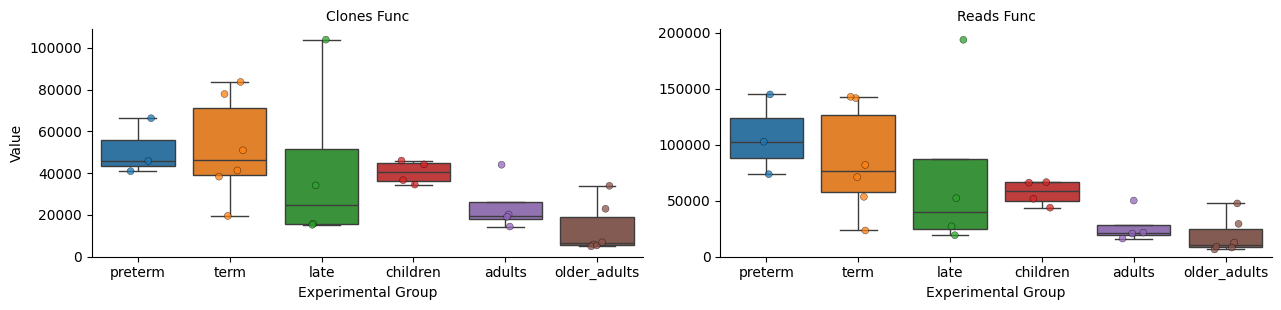

In [2]:
rsplot.clonoset_stats(clonoset_stats_subset, metadata=metadata, group="experimental_group", properties=["clones_func", "reads_func"], aspect=2)

In [10]:
clonoset_stats_subset.sort_values(by="reads_func")

,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
0,o7_nCD8_TRB_1,TRB,5972,5823,5515,308,149,0.024950,6522,6368,154,0.023612,NaN,NaN,NaN,NaN,NaN
17,o2_nCD8_TRB_1,TRB,7077,6818,6027,791,259,0.036597,8325,8056,269,0.032312,NaN,NaN,NaN,NaN,NaN
2,o3_nCD8_TRB_1,TRB,5635,5332,3493,1839,303,0.053771,9313,8941,372,0.039944,NaN,NaN,NaN,NaN,NaN
1,o4_nCD8_TRB_1,TRB,5273,4931,2274,2657,342,0.064859,12971,12500,471,0.036312,NaN,NaN,NaN,NaN,NaN
18,a5_nCD8_TRB_1,TRB,15111,14377,12881,1496,734,0.048574,16879,16091,788,0.046685,NaN,NaN,NaN,NaN,NaN
6,UCB7_nCD8_TRB_1,TRB,16440,15764,13016,2748,676,0.041119,19808,19100,708,0.035743,NaN,NaN,NaN,NaN,NaN
8,a6_nCD8_TRB_1,TRB,19712,19070,17800,1270,642,0.032569,21232,20571,661,0.031132,NaN,NaN,NaN,NaN,NaN
3,a12_nCD8_TRB_1,TRB,20752,20166,19099,1067,586,0.028238,21981,21375,606,0.027569,NaN,NaN,NaN,NaN,NaN
19,UCB12_nCD8_TRB_1,TRB,20368,19465,16504,2961,903,0.044334,24244,23304,940,0.038772,NaN,NaN,NaN,NaN,NaN
10,UCB4_nCD8_TRB_1,TRB,15945,15199,8248,6951,746,0.046786,27886,27005,881,0.031593,NaN,NaN,NaN,NaN,NaN


In [11]:
metadata_check = clonoset_stats_subset.merge(metadata_raw, on="sample_id", validate="one_to_one")
assert (metadata_check["reads_func"] == metadata_check["UMI_functional"]).all()
assert (metadata_check["clones_func"] == metadata_check["clonotypes_functional"]).all()
depth_summary = clonoset_stats_subset.merge(metadata, on="sample_id", validate="one_to_one")
depth_summary.groupby("experimental_group", observed=True)[["clones_func", "reads_func"]].agg(["min", "median", "max"])

clones_func                  reads_func                  
                           min   median     max        min    median     max
experimental_group                                                          
preterm                  40913  45777.0   66274      73563  102609.0  144769
term                     19465  46082.0   83632      23304   76396.0  142640
late                     15199  24929.0  103879      19100   39571.0  193529
children                 34463  40365.5   45987      43652   58813.5   66536
adults                   14377  19618.0   43989      16091   20973.0   50019
older_adults              4931   6320.5   33909       6368   10720.5   47469

## Filters

Глубина функциональной части составляет от 6368 до 193529 наблюдений. Выбираем downsample 6000, чтобы сохранить все 27 образцов, включая o7_nCD8_TRB_1 с минимальной глубиной. Для проверки влияния глубины используем 3000. Исключение малых образцов здесь особенно затронуло бы older_adults

Сохраняем `by_umi=True` как на семинаре, при этом repseq использует reads. Во всех выбранных образцах reads_func совпадает с UMI_functional из метаданных. 

Для F2 фиксируем seed 100 в фильтре. В convergence и diversity задаём seed 100 в функции, а seed фильтра оставляем пустым. Это даёт три разные воспроизводимые подвыборки. Усредняем результаты по трём повторам.

In [12]:
downsample = 6000
func_filter = clf.Filter(functionality="f", by_umi=True)
downsample_filter = clf.Filter(functionality="f", downsample=downsample, by_umi=True, seed=100)
# Для повторов случайность задаёт seed функции.
iteration_filter = clf.Filter(functionality="f", downsample=downsample, by_umi=True)
assert clonoset_stats_subset["reads_func"].min() >= downsample
assert clonoset_stats_subset["umi_func"].isna().all()
downsample_filter

## CDR3 properties

In [13]:
cdr3_properties = stats.calc_cdr3_properties(clonosets_subset, cl_filter=func_filter, cpu=2)
cdr3_properties

Using 2 cores


CalcCDR3aaProperties |#-------------------------------------------------| 1/27 calcultaion(s) processed


CalcCDR3aaProperties |##############------------------------------------| 8/27 calcultaion(s) processed


CalcCDR3aaProperties |######################----------------------------| 12/27 calcultaion(s) processed


CalcCDR3aaProperties |#########################-------------------------| 14/27 calcultaion(s) processed


CalcCDR3aaProperties |###############################-------------------| 17/27 calcultaion(s) processed
CalcCDR3aaProperties |#################################-----------------| 18/27 calcultaion(s) processed
CalcCDR3aaProperties |###################################---------------| 19/27 calcultaion(s) processed


CalcCDR3aaProperties |######################################------------| 21/27 calcultaion(s) processed


CalcCDR3aaProperties |################################################--| 26/27 calcultaion(s) processed
CalcCDR3aaProperties |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,mean_cdr3nt_len,mean_insert_size,zero_insert_freq,mean_frequency,cdr3_5_hydropathy,cdr3_full_hydropathy,cdr3_5_charge,cdr3_full_charge,...,cdr3_5_turn,cdr3_full_turn,cdr3_5_alpha,cdr3_full_alpha,cdr3_5_beta,cdr3_full_beta,cdr3_5_core,cdr3_full_core,cdr3_5_disorder,cdr3_full_disorder
0,o7_nCD8_TRB_1,TRB,43.450534,6.954774,0.027795,0.000172,-3.280779,-3.735773,-0.156407,-0.836840,...,5.851817,15.062949,4.533499,14.413488,4.807051,14.122429,0.288978,0.779796,2.258637,2.791457
1,o4_nCD8_TRB_1,TRB,43.345440,7.112000,0.025520,0.000203,-3.701512,-3.804624,0.075200,-0.489360,...,5.782857,14.944432,4.499513,14.259789,4.866736,14.214689,0.287841,0.777616,2.104160,2.466080
2,o3_nCD8_TRB_1,TRB,43.963203,7.795325,0.013869,0.000188,-4.100179,-4.553506,0.015994,-0.482161,...,5.872966,15.260246,4.476300,14.464089,4.814015,14.335421,0.287575,0.788507,2.315625,2.700593
3,a12_nCD8_TRB_1,TRB,43.383860,7.379135,0.021895,0.000050,-3.858484,-4.227920,-0.082760,-0.683135,...,5.889649,15.061593,4.494039,14.320047,4.801775,14.123816,0.287871,0.776815,2.370667,2.778058
4,UCB1_nCD8_TRB_2,TRB,40.757759,3.236641,0.268110,0.000024,-3.738162,-3.291969,-0.144244,-0.705151,...,5.884342,14.097323,4.483096,13.469358,4.842228,13.313068,0.293609,0.733226,2.162663,2.272664
5,c4_nCD8_TRB_1,TRB,43.241642,7.000698,0.025467,0.000027,-3.636442,-4.126164,-0.097234,-0.746749,...,5.907985,15.041872,4.485906,14.275806,4.801015,14.065160,0.288009,0.775499,2.356183,2.879315
6,UCB7_nCD8_TRB_1,TRB,42.721728,6.344764,0.049581,0.000063,-3.528555,-3.455340,0.008482,-0.535759,...,5.864007,14.834655,4.477363,14.034442,4.824399,13.952395,0.289039,0.766367,2.228010,2.544450
7,c1_nCD8_TRB_1,TRB,43.008672,7.370145,0.022018,0.000022,-3.909778,-3.416638,0.051341,-0.450538,...,5.842508,14.870714,4.489455,14.161060,4.822227,14.046562,0.288655,0.770913,2.335863,2.621648
8,a6_nCD8_TRB_1,TRB,43.272277,7.352341,0.023528,0.000052,-3.341597,-3.769263,-0.134413,-0.749891,...,5.860428,15.005218,4.507167,14.310524,4.823279,14.090764,0.287840,0.775569,2.223227,2.656118
9,UCB8_nCD8_TRB_1,TRB,42.529317,6.283983,0.055565,0.000029,-3.542571,-3.767942,-0.027313,-0.571072,...,5.839796,14.715903,4.507402,14.050153,4.824818,13.861116,0.289364,0.762437,2.204519,2.533000


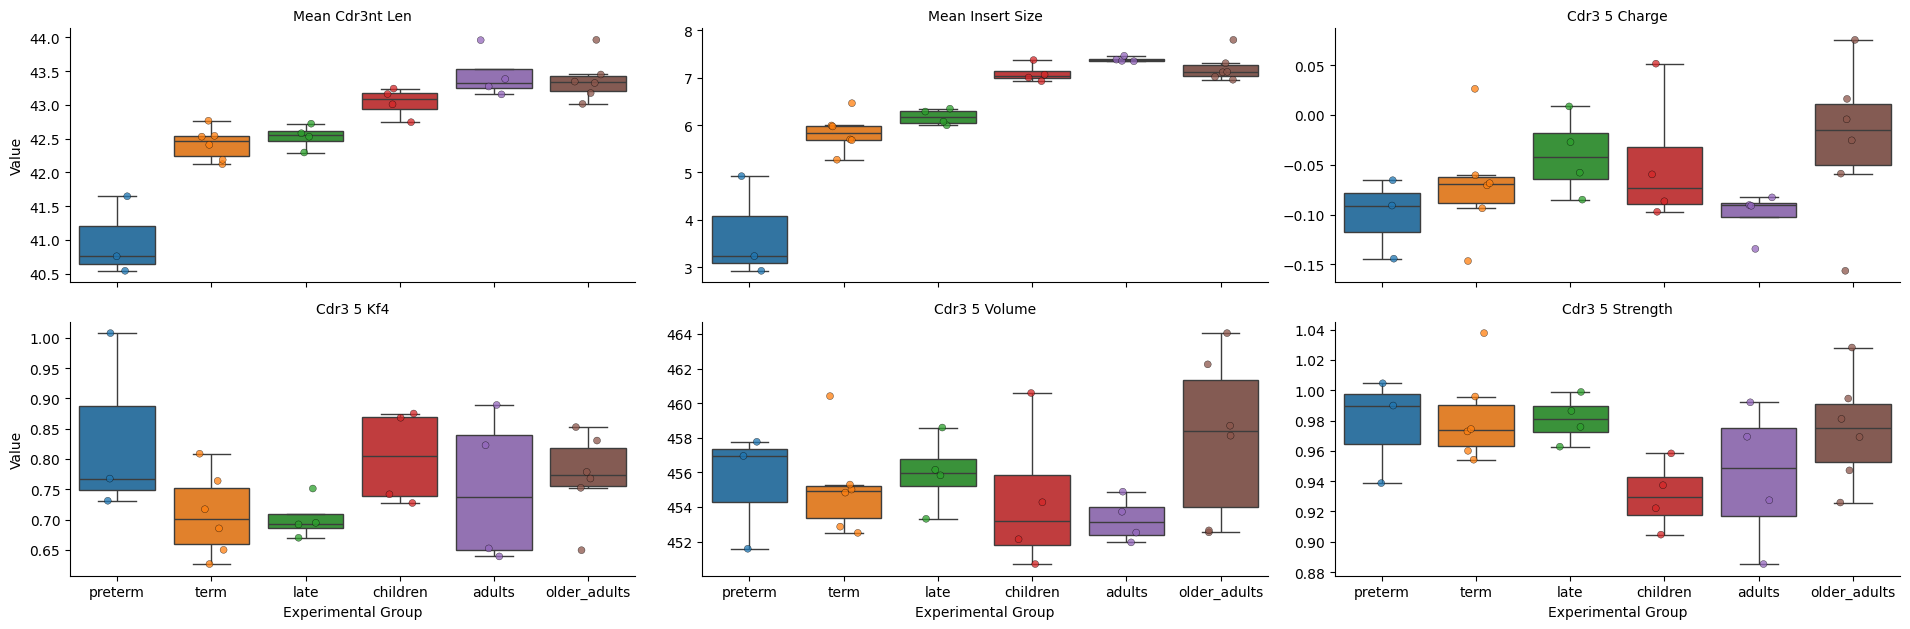

In [3]:
rsplot.cdr3aa_stats(cdr3_properties,
                     metadata=metadata,
                     properties=None,
                     group="experimental_group",
                     split=None,
                     palette=None,
                     height=3.2,
                     aspect=2,
                    )

In [15]:
cdr3_summary = cdr3_properties.merge(metadata, on="sample_id").groupby(
    "experimental_group", observed=True)[["mean_cdr3nt_len", "mean_insert_size"]].mean()
cdr3_summary

,mean_cdr3nt_len,mean_insert_size
experimental_group,,
preterm,40.982275,3.694931
term,42.425713,5.844723
late,42.531588,6.173466
children,43.039089,7.089425
adults,43.442909,7.384133
older_adults,43.378953,7.217052


В preterm средняя длина CDR3 по образцам составляет 40,98 нт, в adults 43,44 нт. Среднее число вставленных нуклеотидов возрастает от 3,69 в preterm до 7,38 в adults. В term и late значения промежуточные, у children и older_adults они близки к adults.

## CDR3len distributions

In [16]:
preterm_late = clonosets_subset.query("experimental_group in ['preterm', 'late']")
preterm_late

,sample_id,chain,filename,experimental_group,donor_id,subset,source
4,UCB1_nCD8_TRB_2,TRB,/home/anna/Bioinformatics305/homework_immune/d...,preterm,UCB1,nCD8,UCB
6,UCB7_nCD8_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,late,UCB7,nCD8,UCB
9,UCB8_nCD8_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,late,UCB8,nCD8,UCB
10,UCB4_nCD8_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,late,UCB4,nCD8,UCB
11,UCB5_nCD8_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,preterm,UCB5,nCD8,UCB
20,UCB11_nCD8_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,preterm,UCB11,nCD8,UCB
25,UCB9_nCD8_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,late,UCB9,nCD8,UCB


In [17]:
cdr3_len_distribs = stats.cdr3_length_distributions(
                                                        preterm_late,
                                                        cl_filter=func_filter,
                                                        cpu=2,
                                                        count_by_freq=True,
                                                        seq_type="aa",
                                                        table="long",
                                                        zero_fill=True,
                                                        verbose=True,
                                                        drop_small_samples=False,
                                                    )
cdr3_len_distribs

Using 2 cores


CalcCDR3LengthDistribution |#######-------------------------------------------| 1/7 calcultaion(s) processed


CalcCDR3LengthDistribution |##################################################| 7/7 calcultaion(s) processed


,sample_id,chain,cdr3_length,freq
0,UCB11_nCD8_TRB_1,TRB,4,0.000014
1,UCB11_nCD8_TRB_1,TRB,5,0.000041
2,UCB11_nCD8_TRB_1,TRB,6,0.000035
3,UCB11_nCD8_TRB_1,TRB,7,0.000104
4,UCB11_nCD8_TRB_1,TRB,8,0.000801
...,...,...,...,...
163,UCB9_nCD8_TRB_1,TRB,23,0.000041
164,UCB9_nCD8_TRB_1,TRB,24,0.000016
165,UCB9_nCD8_TRB_1,TRB,26,0.000005
166,UCB9_nCD8_TRB_1,TRB,27,0.000005


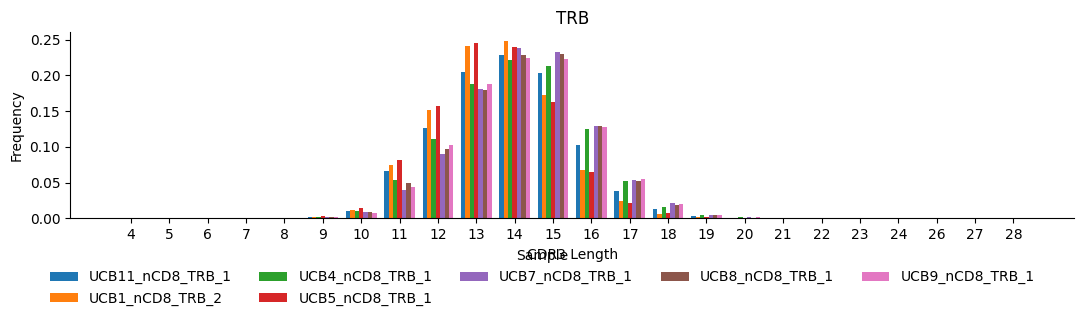

In [4]:
rsplot.cdr3_length_distributions(cdr3_len_distribs)

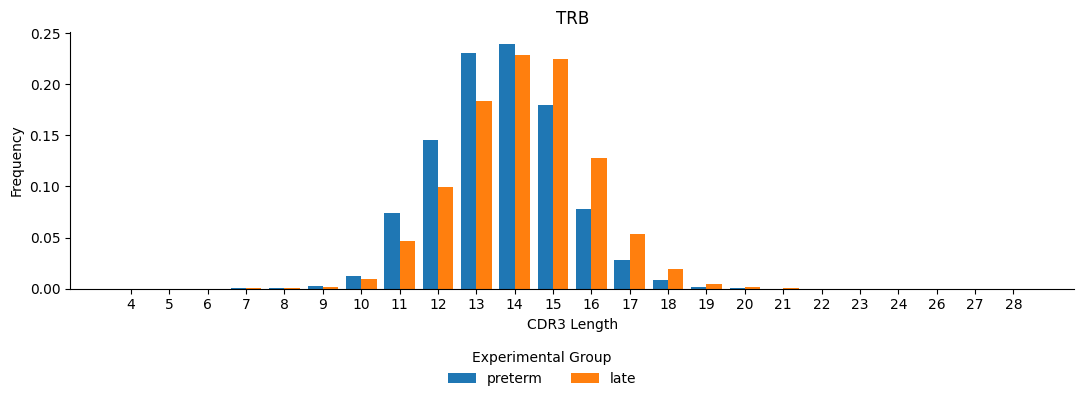

In [5]:
rsplot.cdr3_length_distributions(cdr3_len_distribs, metadata=metadata, group="experimental_group", height=4)

Распределения preterm и late сильно перекрываются. В preterm больше CDR3 длиной 11–13 аминокислот, а в late выше доля длин 15–17. Основная часть обоих распределений приходится на 12–16 аминокислот.

## Segment usage

### V-usage

In [20]:
v_usage = stats.calc_segment_usage(clonosets_subset, segment="v", cl_filter=func_filter, table="long", cpu=2)
v_usage.head()

Using 2 cores


CalcSegmentUsage |#-------------------------------------------------| 1/27 calcultaion(s) processed


CalcSegmentUsage |##############------------------------------------| 8/27 calcultaion(s) processed


CalcSegmentUsage |######################----------------------------| 12/27 calcultaion(s) processed


CalcSegmentUsage |#########################-------------------------| 14/27 calcultaion(s) processed
CalcSegmentUsage |###########################-----------------------| 15/27 calcultaion(s) processed


CalcSegmentUsage |###############################-------------------| 17/27 calcultaion(s) processed
CalcSegmentUsage |#################################-----------------| 18/27 calcultaion(s) processed
CalcSegmentUsage |###################################---------------| 19/27 calcultaion(s) processed


CalcSegmentUsage |######################################------------| 21/27 calcultaion(s) processed


CalcSegmentUsage |################################################--| 26/27 calcultaion(s) processed
CalcSegmentUsage |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,v,usage
0,o7_nCD8_TRB_1,TRB,TRBV10-2,0.003612
1,o4_nCD8_TRB_1,TRB,TRBV10-2,0.002800
2,o3_nCD8_TRB_1,TRB,TRBV10-2,0.001790
3,a12_nCD8_TRB_1,TRB,TRBV10-2,0.006503
4,UCB1_nCD8_TRB_2,TRB,TRBV10-2,0.007395


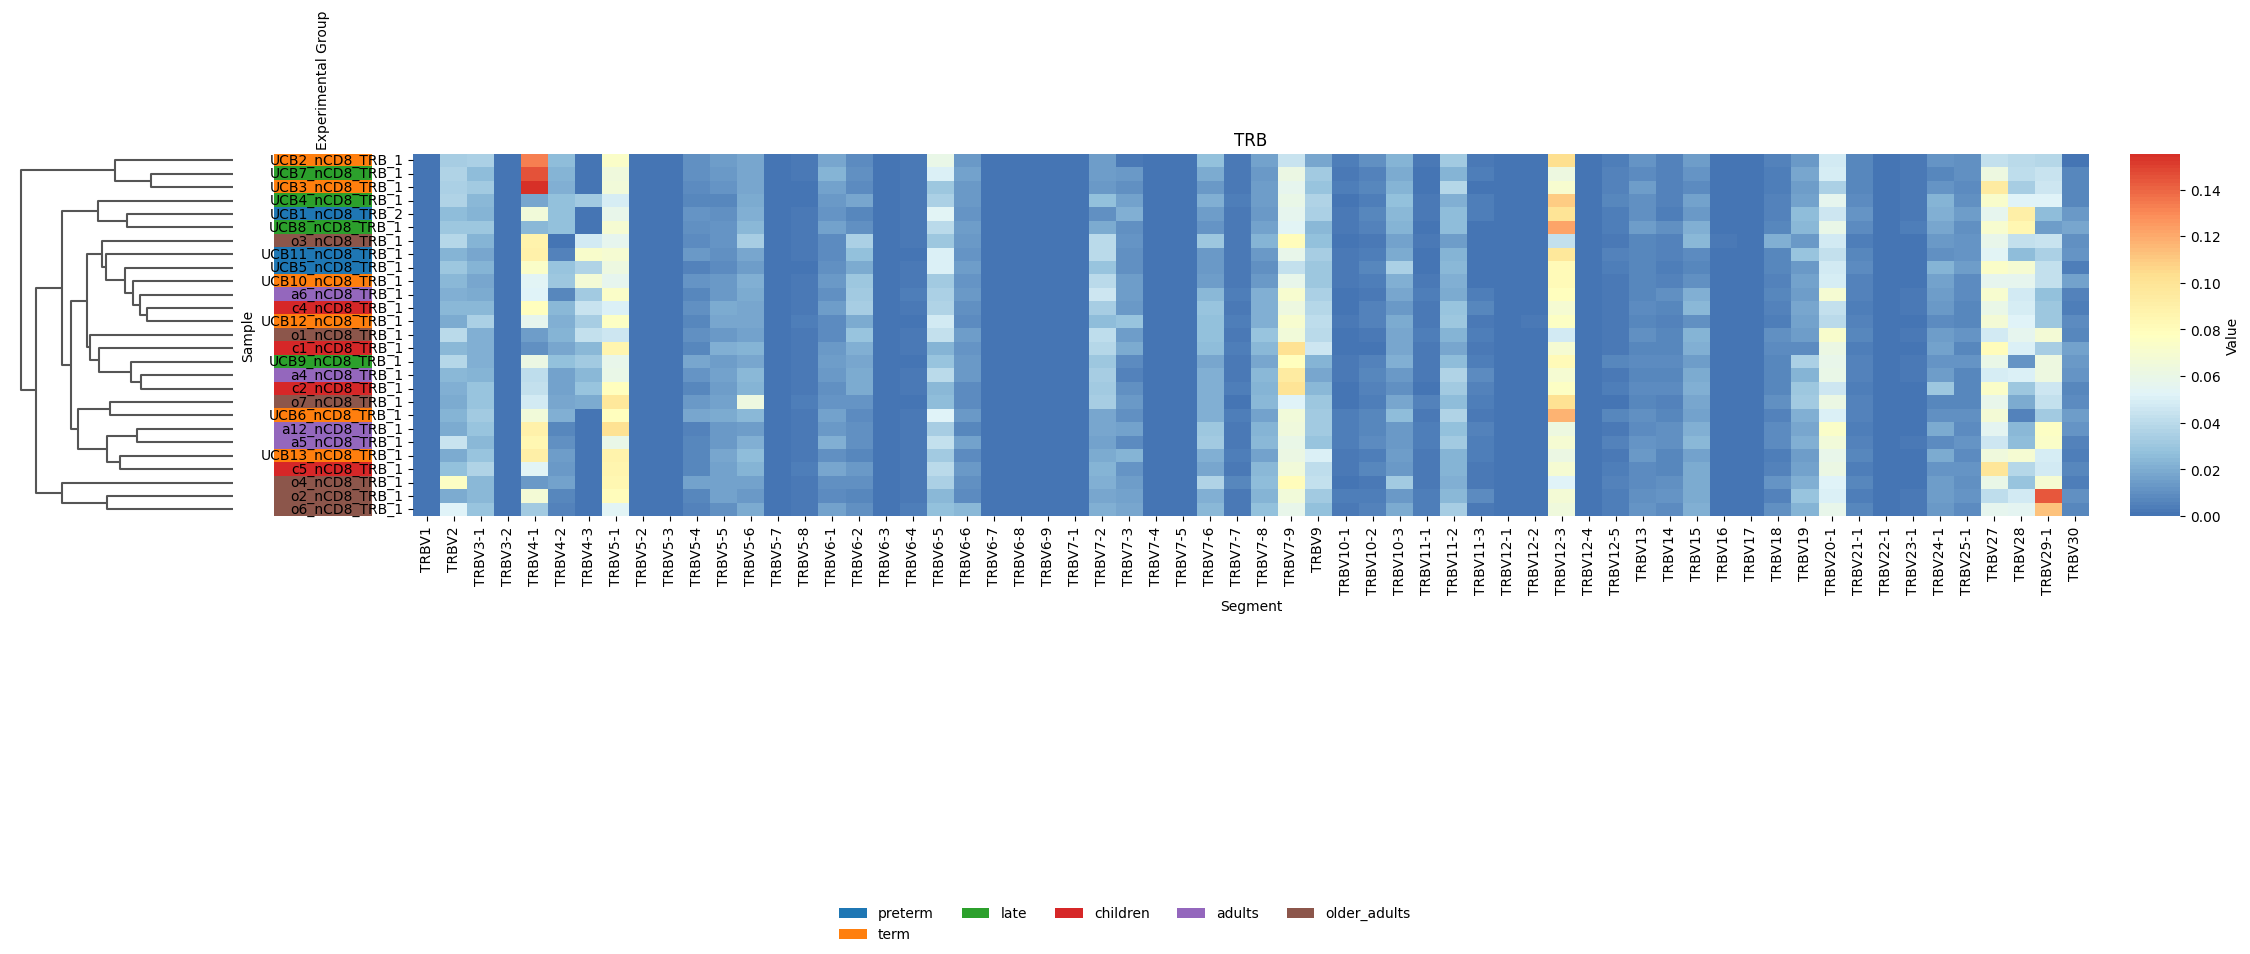

In [6]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="heatmap", height=7)

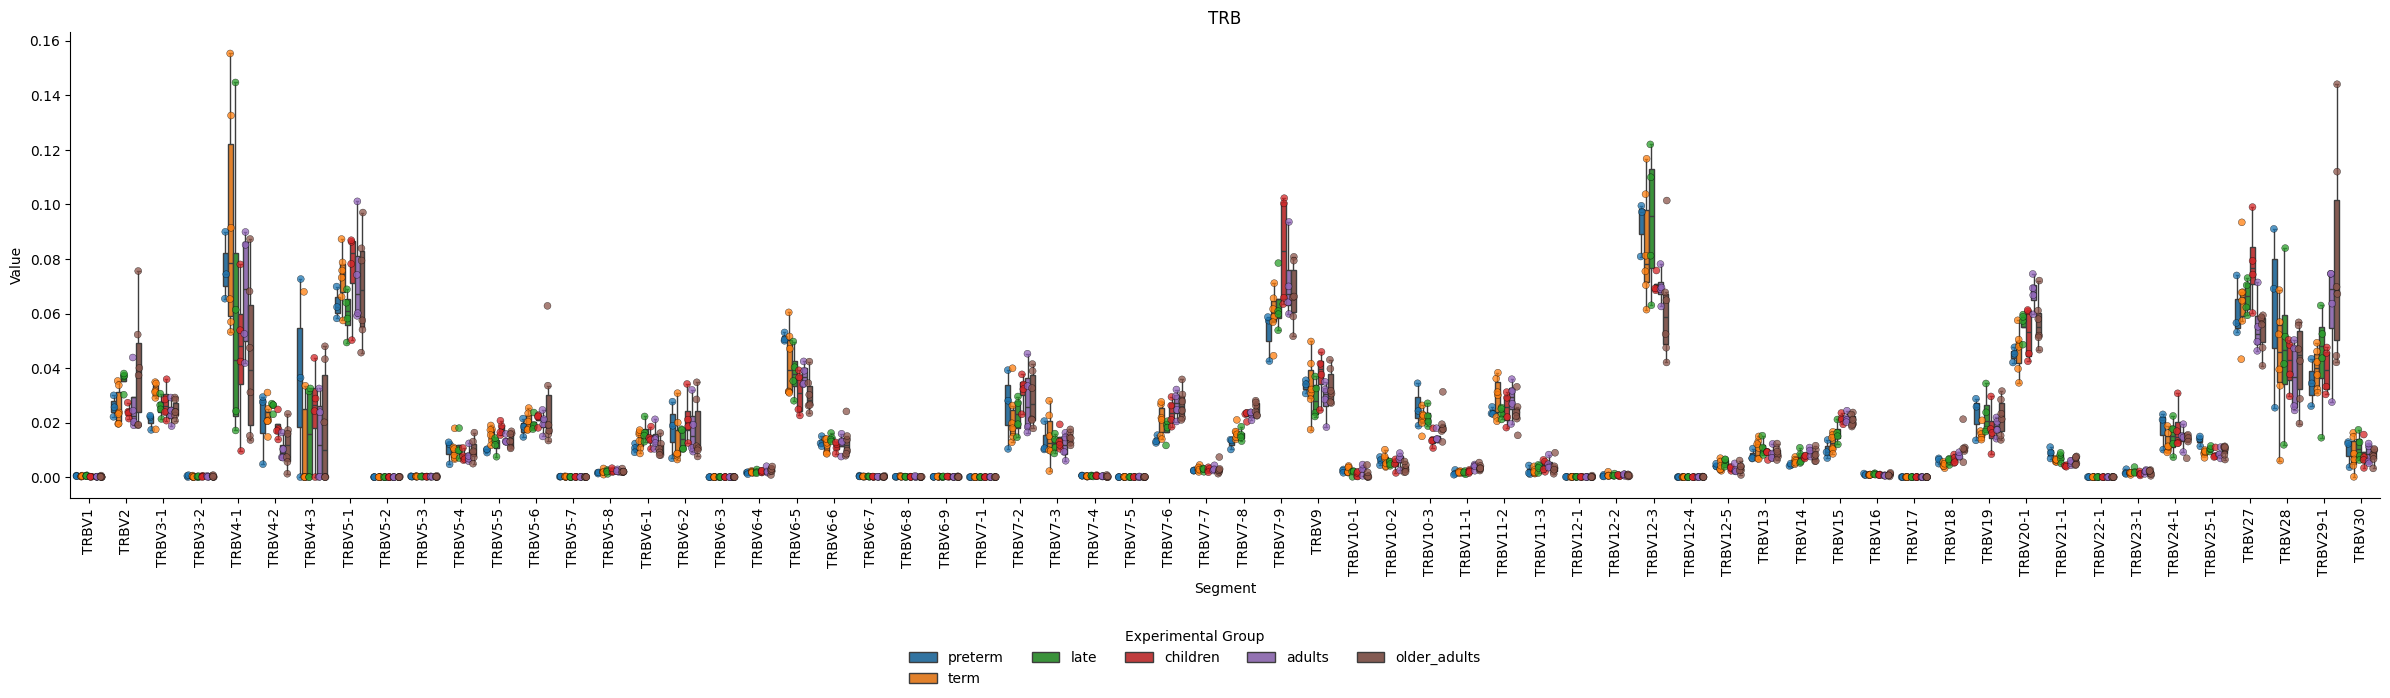

In [7]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, )

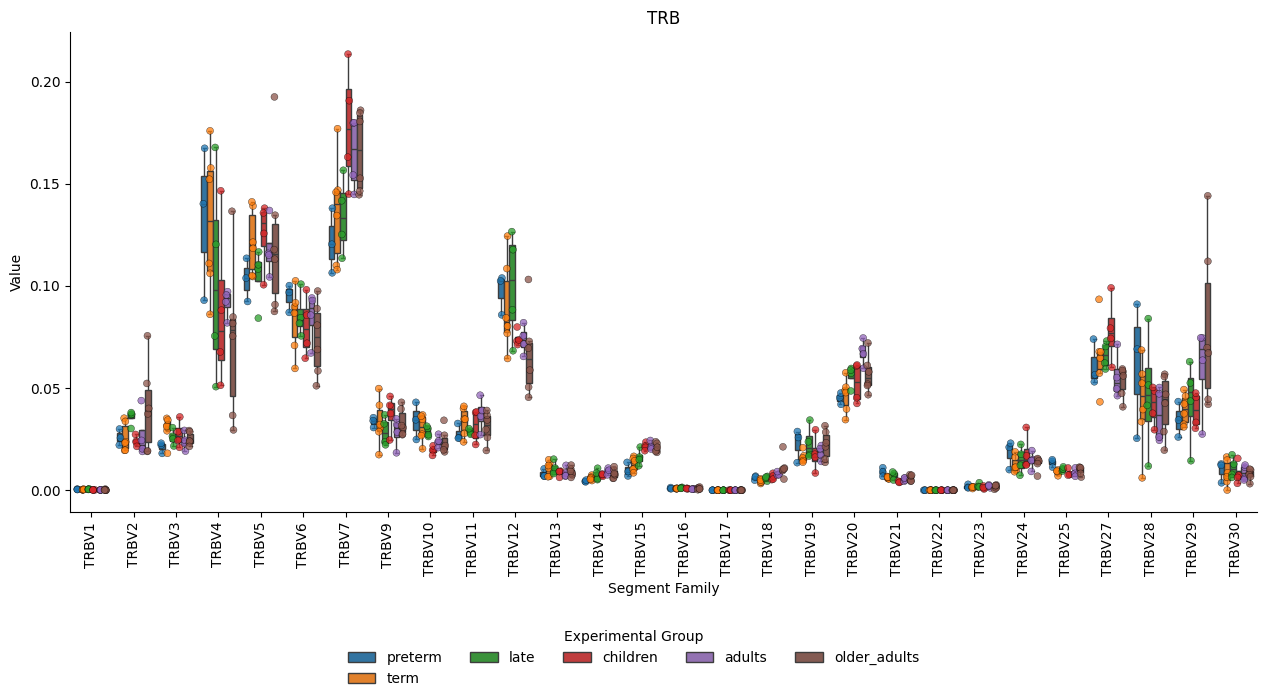

In [8]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, combine_families=True)

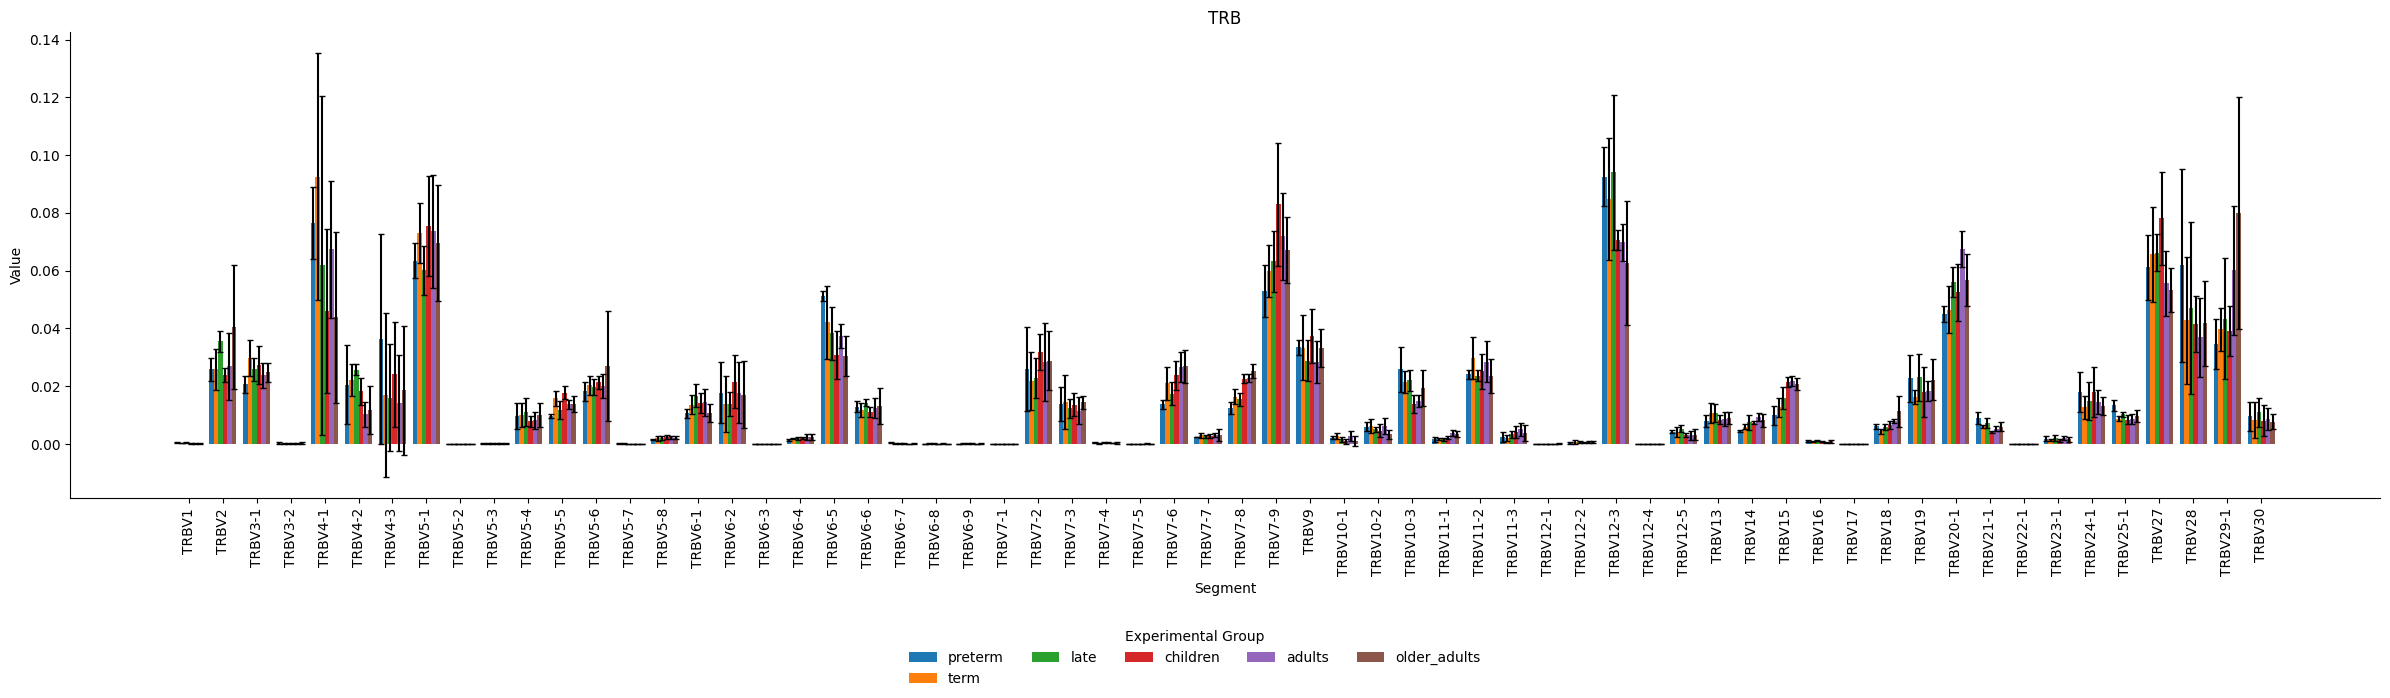

In [9]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)

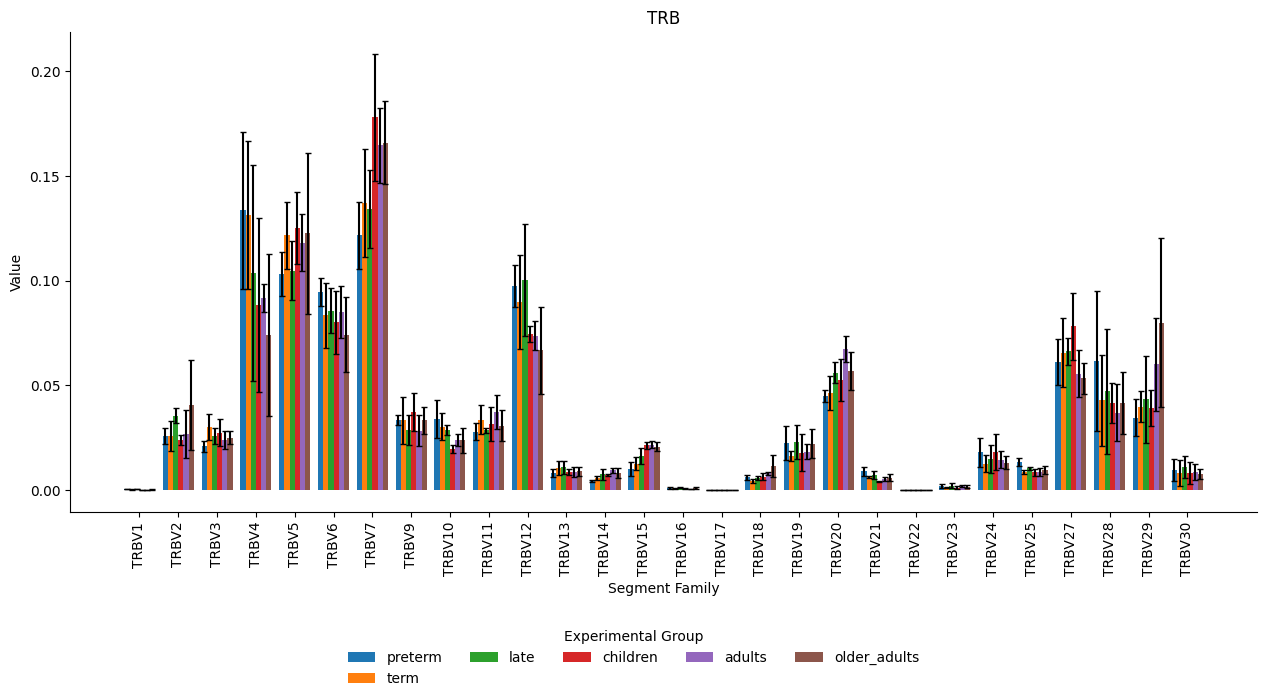

In [10]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7, combine_families=True)

### J-usage

In [26]:
j_usage = stats.calc_segment_usage(clonosets_subset, segment="j", cl_filter=func_filter, table="long", cpu=2)
j_usage.head()

Using 2 cores


CalcSegmentUsage |#-------------------------------------------------| 1/27 calcultaion(s) processed


CalcSegmentUsage |##############------------------------------------| 8/27 calcultaion(s) processed


CalcSegmentUsage |##################--------------------------------| 10/27 calcultaion(s) processed


CalcSegmentUsage |######################----------------------------| 12/27 calcultaion(s) processed


CalcSegmentUsage |#########################-------------------------| 14/27 calcultaion(s) processed


CalcSegmentUsage |###############################-------------------| 17/27 calcultaion(s) processed
CalcSegmentUsage |#################################-----------------| 18/27 calcultaion(s) processed


CalcSegmentUsage |######################################------------| 21/27 calcultaion(s) processed


CalcSegmentUsage |################################################--| 26/27 calcultaion(s) processed
CalcSegmentUsage |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,j,usage
0,o7_nCD8_TRB_1,TRB,TRBJ1-1,0.103329
1,o4_nCD8_TRB_1,TRB,TRBJ1-1,0.075840
2,o3_nCD8_TRB_1,TRB,TRBJ1-1,0.106028
3,a12_nCD8_TRB_1,TRB,TRBJ1-1,0.111392
4,UCB1_nCD8_TRB_2,TRB,TRBJ1-1,0.085600


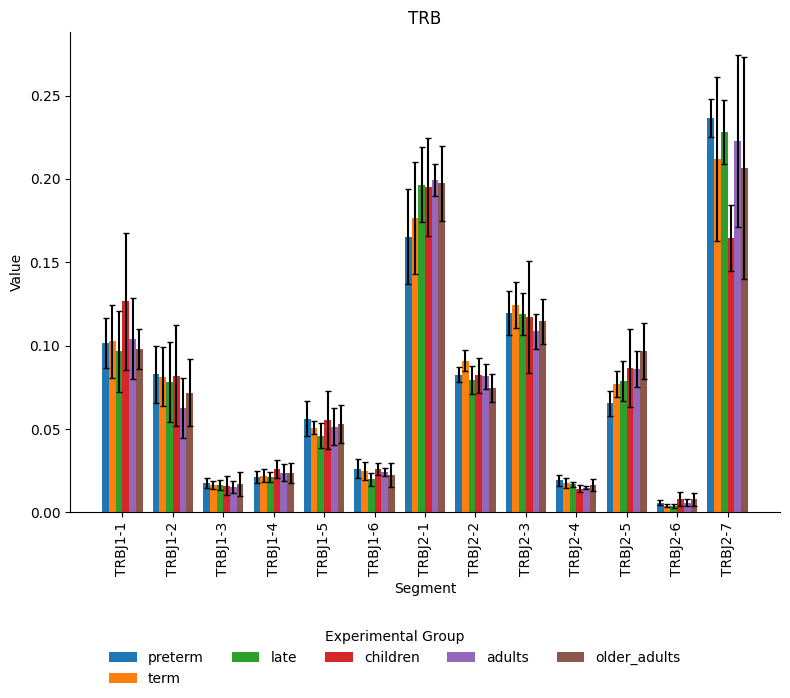

In [11]:
rsplot.segment_usage(j_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)

В среднем по образцам наиболее часты TRBV12-3 (7,8%), TRBV5-1 (7,0%) и TRBV7-9 (6,6%). Лидирующий V-сегмент зависит от группы. В preterm и late это TRBV12-3, в term TRBV4-1, в children TRBV7-9, в adults TRBV5-1, в older_adults TRBV29-1. Среди J-сегментов преобладают TRBJ2-7 (21,0%) и TRBJ2-1 (18,9%).

## Convergence

In [28]:
convergence = stats.calc_convergence(clonosets_subset, cl_filter=iteration_filter,
                                     seed=100, iterations=3, cpu=2)
convergence

CalcConvergence settings: seed=100, downsample=6000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores


CalcClonosetStats |#-------------------------------------------------| 1/27 calcultaion(s) processed


CalcClonosetStats |###########---------------------------------------| 6/27 calcultaion(s) processed


CalcClonosetStats |##############------------------------------------| 8/27 calcultaion(s) processed


CalcClonosetStats |##################--------------------------------| 10/27 calcultaion(s) processed


CalcClonosetStats |######################----------------------------| 12/27 calcultaion(s) processed


... (8 outputs left out)

CalcConvergence |###############################-------------------| 17/27 calcultaion(s) processed
CalcConvergence |#################################-----------------| 18/27 calcultaion(s) processed
CalcConvergence |###################################---------------| 19/27 calcultaion(s) processed


CalcConvergence |######################################------------| 21/27 calcultaion(s) processed


CalcConvergence |################################################--| 26/27 calcultaion(s) processed
CalcConvergence |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,convergence,convergence_v,convergence_vj
0,o7_nCD8_TRB_1,TRB,1.005947,1.001233,1.001233
1,o4_nCD8_TRB_1,TRB,1.003919,1.002161,1.002161
2,o3_nCD8_TRB_1,TRB,1.002280,1.000700,1.000700
3,a12_nCD8_TRB_1,TRB,1.004168,1.000797,1.000797
4,UCB1_nCD8_TRB_2,TRB,1.081831,1.015663,1.015663
5,c4_nCD8_TRB_1,TRB,1.004035,1.000591,1.000591
6,UCB7_nCD8_TRB_1,TRB,1.008250,1.002334,1.002334
7,c1_nCD8_TRB_1,TRB,1.002869,1.000409,1.000409
8,a6_nCD8_TRB_1,TRB,1.007783,1.002121,1.002121
9,UCB8_nCD8_TRB_1,TRB,1.009995,1.001483,1.001483


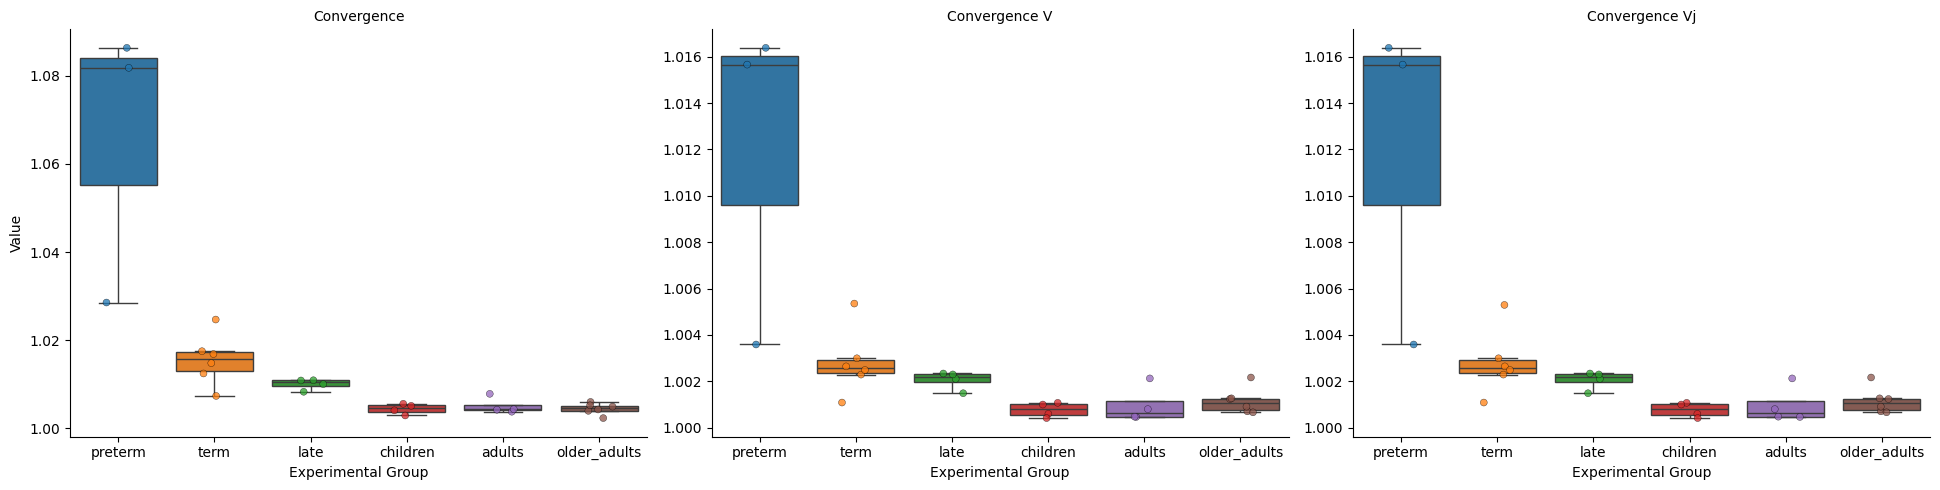

In [12]:
rsplot.convergence(convergence,
                     metadata=metadata,
                     group="experimental_group",
                     height=5,
                     aspect=1.3
                  )

Медиана convergence выше всего в preterm, 1,082. В term она равна 1,016, в late 1,010, в группах периферической крови около 1,004–1,005. Учёт V-гена снижает значения почти до единицы; в preterm медиана остаётся выше, 1,016. то есть - более частое кодирование одной CDR3aa разными CDR3nt в preterm.

## Diversity stats

In [30]:
diversity_stats = stats.calc_diversity_stats(clonosets_subset, cl_filter=iteration_filter,
                                             seed=100, cpu=2, iterations=3,
                                             drop_small_samples=False)
diversity_stats

CalcDiversityStats settings: seed=100, downsample=6000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores


CalcClonosetStats |#-------------------------------------------------| 1/27 calcultaion(s) processed


CalcClonosetStats |###########---------------------------------------| 6/27 calcultaion(s) processed


CalcClonosetStats |##############------------------------------------| 8/27 calcultaion(s) processed


CalcClonosetStats |##################--------------------------------| 10/27 calcultaion(s) processed


CalcClonosetStats |######################----------------------------| 12/27 calcultaion(s) processed


... (8 outputs left out)

CalcDiversityStats |###############################-------------------| 17/27 calcultaion(s) processed
CalcDiversityStats |#################################-----------------| 18/27 calcultaion(s) processed
CalcDiversityStats |###################################---------------| 19/27 calcultaion(s) processed


CalcDiversityStats |######################################------------| 21/27 calcultaion(s) processed


CalcDiversityStats |################################################--| 26/27 calcultaion(s) processed
CalcDiversityStats |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,o7_nCD8_TRB_1,TRB,5502.666667,0.984808,0.015192,8.482139,59673.093732,5502.666667,67914.863295,0.129278,0.454809,0.000766,1305.579494,0.999234,0.023556,0.080507
1,o4_nCD8_TRB_1,TRB,3353.333333,0.959303,0.040697,7.787306,6269.248323,3353.333333,6654.682725,0.655056,0.244128,0.001444,696.392087,0.998556,0.030722,0.339612
2,o3_nCD8_TRB_1,TRB,4058.000000,0.971165,0.028835,8.068866,9909.946749,4058.000000,10466.953213,0.508556,0.267045,0.000735,1364.012458,0.999265,0.014333,0.266630
3,a12_nCD8_TRB_1,TRB,5894.000000,0.999174,0.000826,8.674521,181340.040769,5894.000000,182553.760937,0.034444,0.491007,0.000173,5784.106218,0.999827,0.000611,0.017378
4,UCB1_nCD8_TRB_2,TRB,5564.666667,0.996314,0.003686,8.592397,46298.279297,5564.666667,48631.472952,0.135056,0.460871,0.000196,5113.503557,0.999804,0.000944,0.068268
5,c4_nCD8_TRB_1,TRB,5696.000000,0.997546,0.002454,8.626297,61603.946751,5696.000000,66021.108060,0.097222,0.473314,0.000186,5377.458434,0.999814,0.001278,0.048373
6,UCB7_nCD8_TRB_1,TRB,5637.333333,0.997285,0.002715,8.613717,49648.771138,5637.333333,49606.114311,0.117167,0.467832,0.000188,5316.038000,0.999812,0.000611,0.057004
7,c1_nCD8_TRB_1,TRB,5763.333333,0.998229,0.001771,8.643932,76789.518604,5763.333333,76554.813292,0.077167,0.479467,0.000180,5543.629166,0.999820,0.000500,0.037958
8,a6_nCD8_TRB_1,TRB,5862.666667,0.998875,0.001125,8.666598,146594.259500,5862.666667,151464.274430,0.043889,0.488287,0.000175,5710.060000,0.999825,0.000778,0.022434
9,UCB8_nCD8_TRB_1,TRB,5663.666667,0.997483,0.002517,8.620073,53383.931421,5663.666667,53506.519881,0.108944,0.470305,0.000186,5362.574916,0.999814,0.000667,0.053080


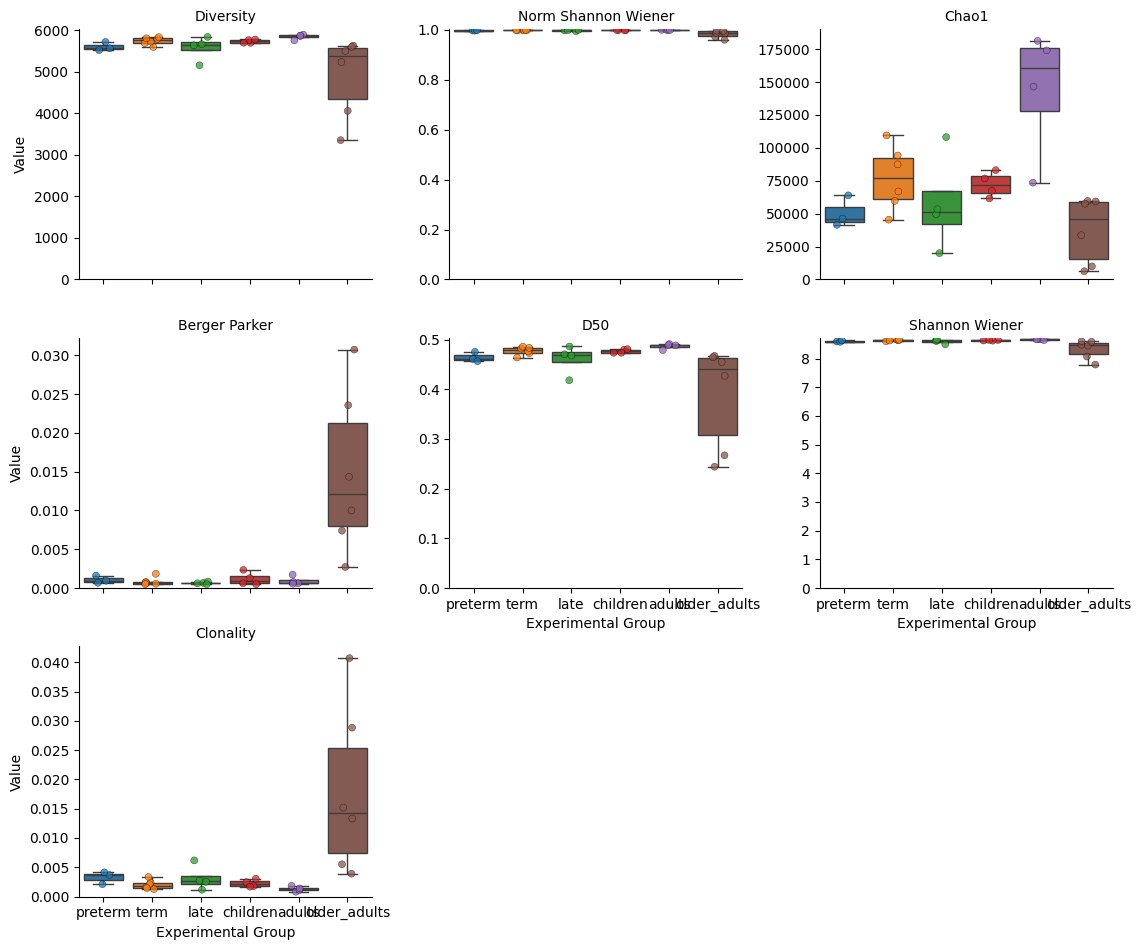

In [13]:
rsplot.diversity_stats(diversity_stats, metadata=metadata, group="experimental_group",
                       properties=["diversity", "norm_shannon_wiener", "chao1", "berger_parker",
                                   "d50", "shannon_wiener", "clonality"])

In [32]:
diversity_summary = diversity_stats.merge(metadata, on="sample_id").groupby(
    "experimental_group", observed=True)[["diversity", "shannon_wiener", "clonality"]].median()
diversity_summary

,diversity,shannon_wiener,clonality
experimental_group,,,
preterm,5564.666667,8.592397,0.003686
term,5757.166667,8.642202,0.001846
late,5650.500000,8.616895,0.002616
children,5730.666667,8.635115,0.002113
adults,5865.333333,8.665909,0.001257
older_adults,5368.833333,8.465559,0.014261


При глубине 6000 медиана diversity максимальна в adults (5865) и минимальна в older_adults (5369). В older_adults также ниже медиана Shannon (8,47 против 8,67 в adults) и выше clonality (0,0143 против 0,0013). Медиана доли крупнейшего клона составляет 1,22% в older_adults и 0,07% в adults

## Rarefaction

In [33]:
rarefaction_points_ucb = stats.calc_rarefaction_curve(
    clonosets_subset, cl_filter=func_filter, iterations=3, seed=100, cpu=2)
rarefaction_points_ucb.head()

Using 2 cores


CalcRarefactionPoints |#-------------------------------------------------| 1/27 calcultaion(s) processed


CalcRarefactionPoints |##############------------------------------------| 8/27 calcultaion(s) processed


CalcRarefactionPoints |##################--------------------------------| 10/27 calcultaion(s) processed


CalcRarefactionPoints |######################----------------------------| 12/27 calcultaion(s) processed


CalcRarefactionPoints |#########################-------------------------| 14/27 calcultaion(s) processed


CalcRarefactionPoints |###############################-------------------| 17/27 calcultaion(s) processed
CalcRarefactionPoints |#################################-----------------| 18/27 calcultaion(s) processed
CalcRarefactionPoints |###################################---------------| 19/27 calcultaion(s) processed


CalcRarefactionPoints |######################################------------| 21/27 calcultaion(s) processed


CalcRarefactionPoints |################################################--| 26/27 calcultaion(s) processed
CalcRarefactionPoints |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,rarefaction_depth,diversity
0,UCB10_nCD8_TRB_1,TRB,32,32.000000
1,UCB10_nCD8_TRB_1,TRB,100,100.000000
2,UCB10_nCD8_TRB_1,TRB,316,315.000000
3,UCB10_nCD8_TRB_1,TRB,1000,994.666667
4,UCB10_nCD8_TRB_1,TRB,3162,3108.000000


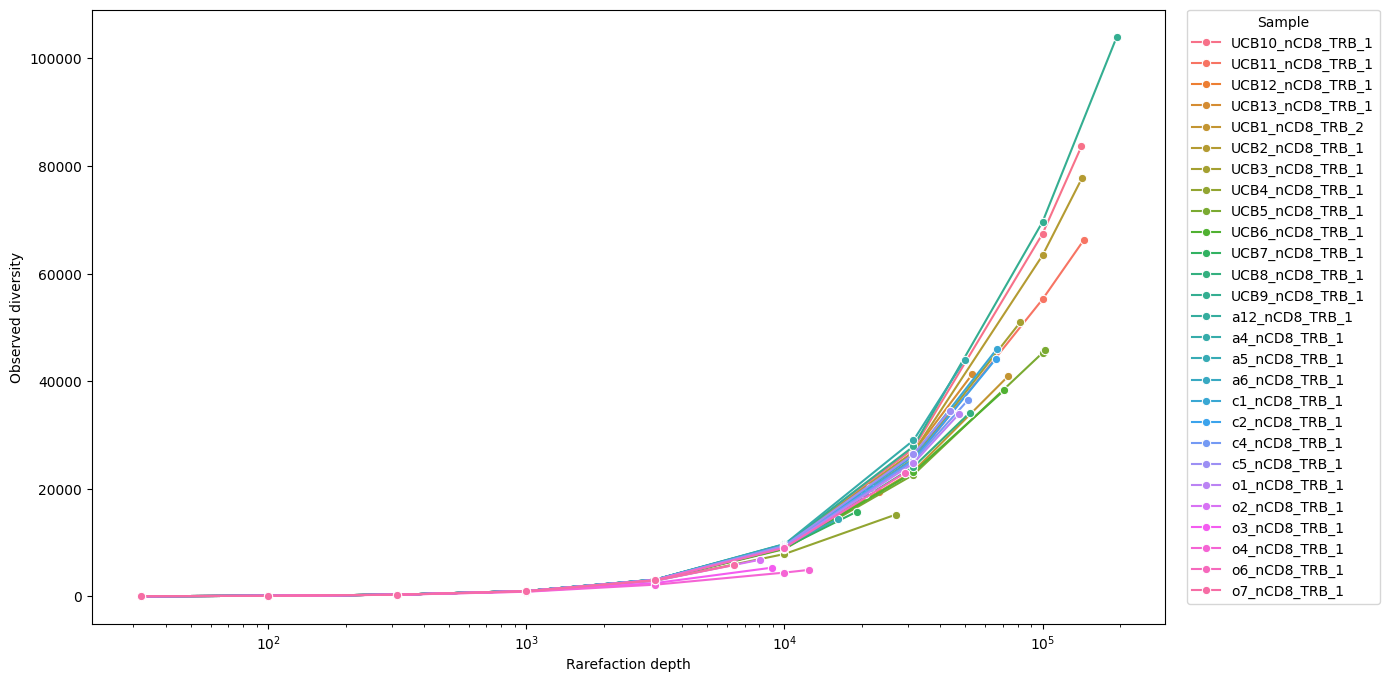

In [14]:
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=True, aspect=2, height=7)

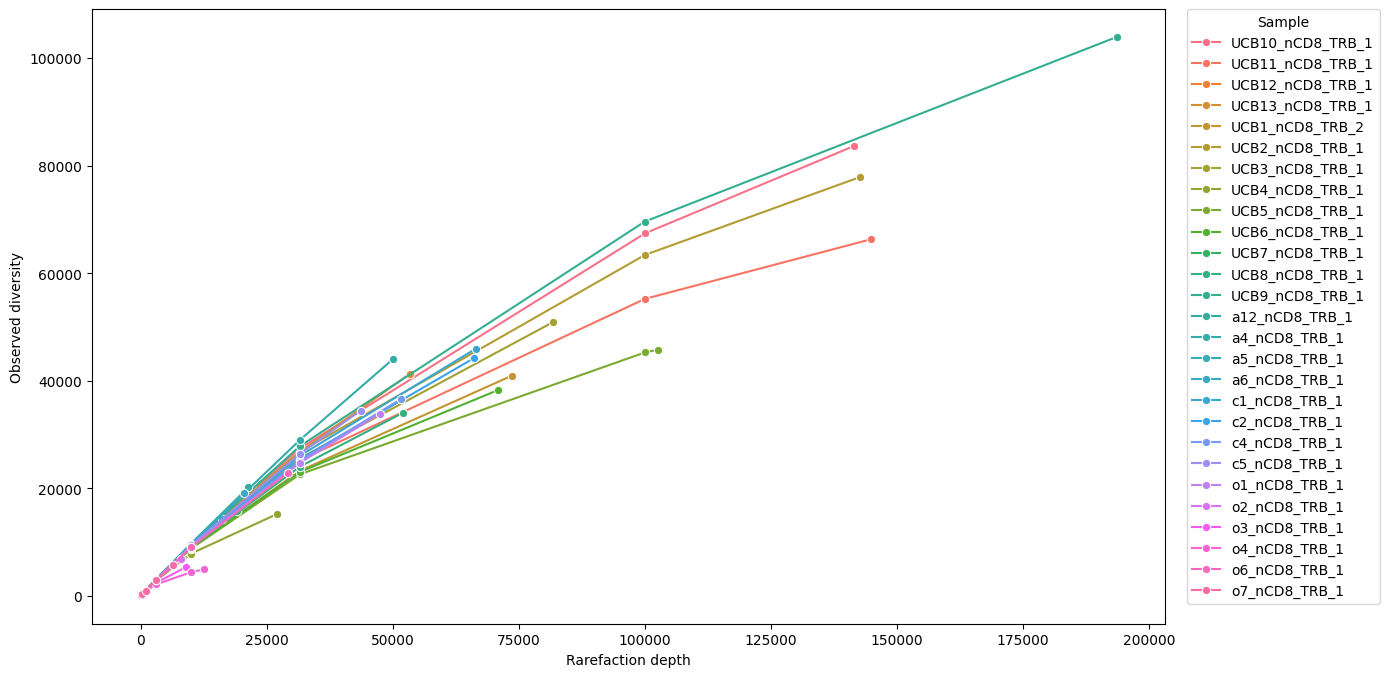

In [15]:
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=False, aspect=2, height=7)

Кривые продолжают расти до максимальной доступной глубины. Полного насыщения не видно, поэтому дополнительное секвенирование может выявить редкие клонотипы. Различия конечных значений также зависят от глубины исходных образцов.

## Beta-diversity

In [36]:
f2 = beta.metrics(clonosets_subset, cl_filter=downsample_filter,
                              overlap_type="aaV", metrics=["f2"], cpu=2)
beta_diversity = {"f2": f2}
assert np.allclose(f2, f2.T)
assert np.allclose(np.diag(f2), 1)
f2

Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV


Reading clonosets |##################################################| 27/27 sample(s) processed
Using 2 cores


Intersecting clonosets |--------------------------------------------------| 2/351 pairs processed


Intersecting clonosets |--------------------------------------------------| 4/351 pairs processed


Intersecting clonosets |--------------------------------------------------| 6/351 pairs processed


Intersecting clonosets |#-------------------------------------------------| 13/351 pairs processed


... (90 outputs left out)

Intersecting clonosets |#################################################-| 347/351 pairs processed


Intersecting clonosets |#################################################-| 349/351 pairs processed


Intersecting clonosets |##################################################| 351/351 pairs processed


sample2,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB12_nCD8_TRB_1,UCB13_nCD8_TRB_1,UCB1_nCD8_TRB_2,UCB2_nCD8_TRB_1,UCB3_nCD8_TRB_1,UCB4_nCD8_TRB_1,UCB5_nCD8_TRB_1,UCB6_nCD8_TRB_1,...,c1_nCD8_TRB_1,c2_nCD8_TRB_1,c4_nCD8_TRB_1,c5_nCD8_TRB_1,o1_nCD8_TRB_1,o2_nCD8_TRB_1,o3_nCD8_TRB_1,o4_nCD8_TRB_1,o6_nCD8_TRB_1,o7_nCD8_TRB_1
sample1,,,,,,,,,,,,,,,,,,,,,
UCB10_nCD8_TRB_1,1.000000,0.009012,0.004467,0.005581,0.013927,0.004069,0.004443,0.003853,0.016817,0.003943,...,0.002333,0.002776,0.001000,0.002069,0.003511,0.002069,0.001236,0.000902,0.001858,0.002471
UCB11_nCD8_TRB_1,0.009012,1.000000,0.006425,0.008887,0.027356,0.007967,0.011158,0.006759,0.023978,0.004857,...,0.002496,0.003179,0.002260,0.003374,0.002638,0.003609,0.001858,0.002284,0.001775,0.003500
UCB12_nCD8_TRB_1,0.004467,0.006425,1.000000,0.005743,0.014548,0.005012,0.005671,0.004406,0.014800,0.002471,...,0.001333,0.001927,0.001236,0.002471,0.002146,0.002138,0.001305,0.001049,0.001000,0.001971
UCB13_nCD8_TRB_1,0.005581,0.008887,0.005743,1.000000,0.015603,0.005504,0.008546,0.005158,0.015014,0.003236,...,0.002638,0.003073,0.002260,0.002207,0.001402,0.003753,0.000333,0.000569,0.000736,0.003024
UCB1_nCD8_TRB_2,0.013927,0.027356,0.014548,0.015603,1.000000,0.016077,0.027174,0.012717,0.057647,0.010121,...,0.003207,0.005581,0.003215,0.007870,0.003835,0.006440,0.001707,0.004152,0.002329,0.003242
UCB2_nCD8_TRB_1,0.004069,0.007967,0.005012,0.005504,0.016077,1.000000,0.007947,0.005536,0.016503,0.003845,...,0.001500,0.002715,0.002236,0.001638,0.001736,0.002546,0.000691,0.000760,0.001122,0.003207
UCB3_nCD8_TRB_1,0.004443,0.011158,0.005671,0.008546,0.027174,0.007947,1.000000,0.006743,0.024066,0.004012,...,0.002242,0.002374,0.002167,0.003231,0.001971,0.003266,0.001358,0.001760,0.001638,0.003093
UCB4_nCD8_TRB_1,0.003853,0.006759,0.004406,0.005158,0.012717,0.005536,0.006743,1.000000,0.014455,0.004187,...,0.002260,0.002049,0.002138,0.002731,0.001805,0.001609,0.000622,0.001305,0.001244,0.002138
UCB5_nCD8_TRB_1,0.016817,0.023978,0.014800,0.015014,0.057647,0.016503,0.024066,0.014455,1.000000,0.009382,...,0.004825,0.004967,0.002191,0.005825,0.003218,0.005605,0.000902,0.002649,0.003065,0.004341


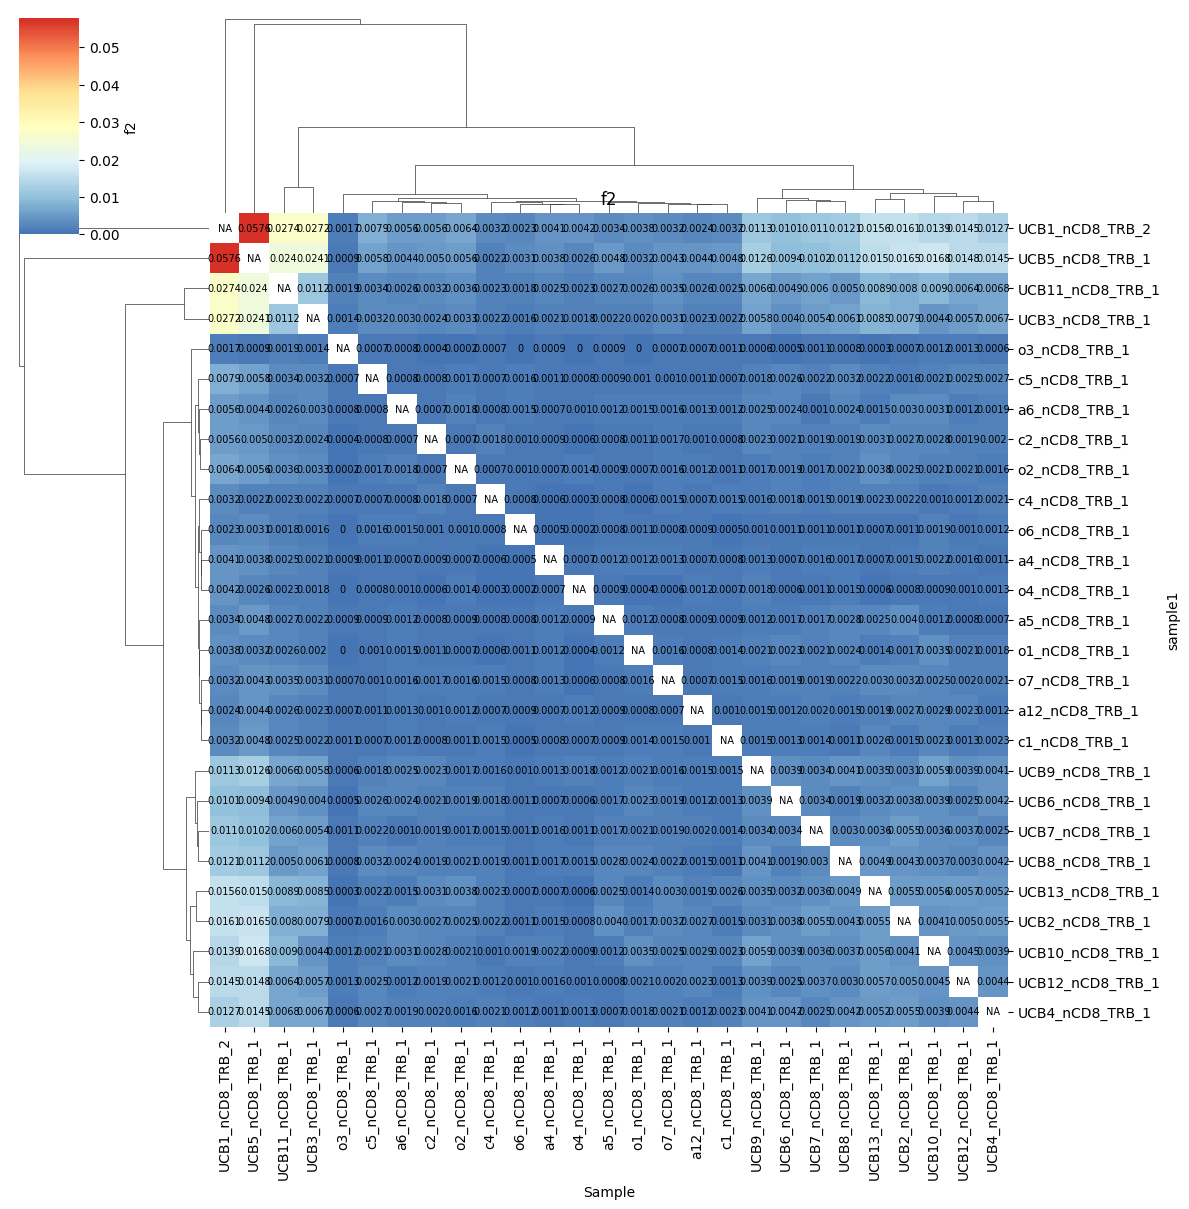

In [16]:
rsplot.beta_metric(beta_diversity, metric="f2", ignore_diagonal=True,
                   hclust=True, log_values=False, height=12)

In [38]:
# Усредняем сходство пар по группам без диагонали.
f2_pairs = f2.where(~np.eye(len(f2), dtype=bool)).stack().rename("f2").reset_index()
f2_pairs.columns = ["sample_id_1", "sample_id_2", "f2"]
group_by_sample = metadata.set_index("sample_id")["experimental_group"]
f2_pairs["group_1"] = f2_pairs["sample_id_1"].map(group_by_sample)
f2_pairs["group_2"] = f2_pairs["sample_id_2"].map(group_by_sample)
f2_pairs.groupby(["group_1", "group_2"], observed=True)["f2"].mean().unstack()

group_2,preterm,term,late,children,adults,older_adults
group_1,,,,,,
preterm,0.036327,0.013463,0.009976,0.004082,0.003625,0.003175
term,0.013463,0.004966,0.004382,0.002137,0.002028,0.001750
late,0.009976,0.004382,0.003550,0.001978,0.001639,0.001533
children,0.004082,0.002137,0.001978,0.001043,0.000889,0.000963
adults,0.003625,0.002028,0.001639,0.000889,0.000990,0.001023
older_adults,0.003175,0.001750,0.001533,0.000963,0.001023,0.000679


Медиана F2 между образцами равна 0,00194. Наибольшее среднее внутригрупповое сходство наблюдается в preterm (0,0363), затем в term (0,00497) и late (0,00355). В группах периферической крови оно составляет 0,00068–0,00104. Максимум F2 равен 0,0576 для пары UCB1_nCD8_TRB_2 и UCB5_nCD8_TRB_1 из preterm.

### MDS for metric

In [39]:
ucb_mds = beta.mds(beta_diversity, metric="f2")
assert np.isfinite(ucb_mds[["MDS1", "MDS2"]]).all().all()
ucb_mds

,sample_id,MDS1,MDS2
0,UCB10_nCD8_TRB_1,-0.056492,0.139184
1,UCB11_nCD8_TRB_1,-0.137889,-0.155933
2,UCB12_nCD8_TRB_1,-0.180679,-0.093826
3,UCB13_nCD8_TRB_1,0.034817,0.330763
4,UCB1_nCD8_TRB_2,-0.001956,-0.218688
5,UCB2_nCD8_TRB_1,-0.100296,0.181319
6,UCB3_nCD8_TRB_1,-0.115488,-0.150960
7,UCB4_nCD8_TRB_1,0.055399,0.202135
8,UCB5_nCD8_TRB_1,0.114967,-0.132470
9,UCB6_nCD8_TRB_1,0.097810,0.497820


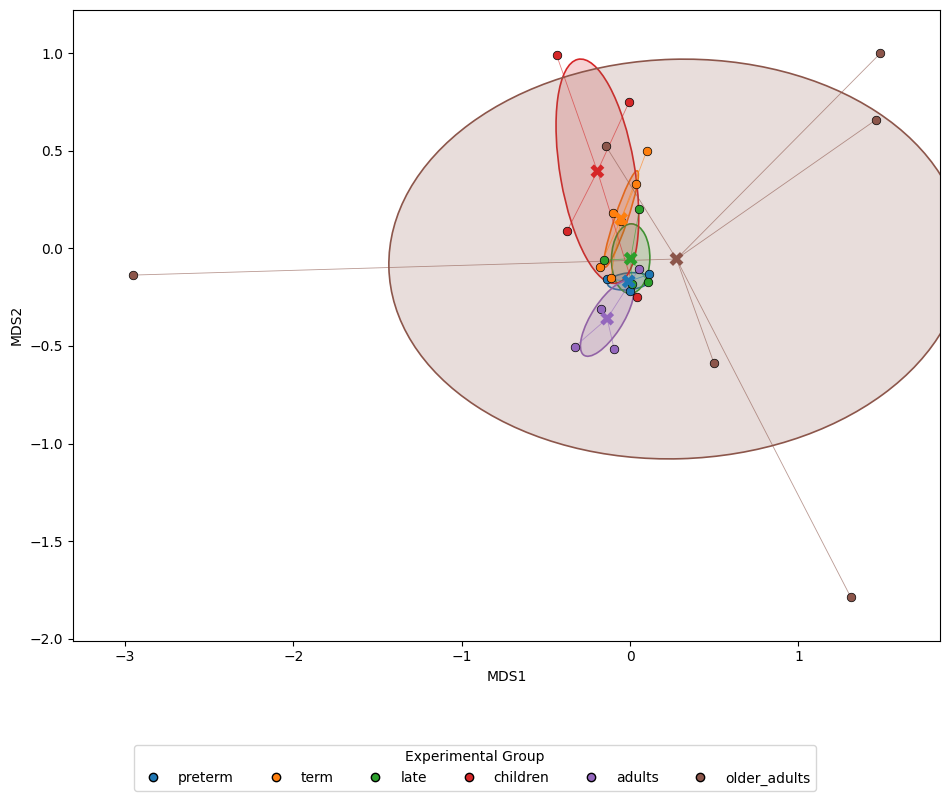

In [17]:
rsplot.beta_mds(ucb_mds, metadata=metadata, group="experimental_group", centroids=True, dispersion=True, height=8)

Образцы preterm расположены компактно в центральной области и перекрываются с частью term и late. Большинство adults смещено вниз, часть children вверх по второй координате. Самый большой разброс наблюдается у older_adults. Полного разделения опять нет :(

## Влияние downsample

In [41]:
downsample_small = 3000
small_filter = clf.Filter(functionality="f", downsample=downsample_small, by_umi=True)
diversity_small = stats.calc_diversity_stats(clonosets_subset, cl_filter=small_filter,
                                             iterations=3, seed=100, cpu=2)
depth_comparison = pd.concat([
    diversity_small.assign(downsample=downsample_small),
    diversity_stats.assign(downsample=downsample)], ignore_index=True).merge(metadata, on="sample_id")
depth_comparison.groupby(["experimental_group", "downsample"], observed=True)["diversity"].median().unstack()

CalcDiversityStats settings: seed=100, downsample=3000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores


CalcClonosetStats |#-------------------------------------------------| 1/27 calcultaion(s) processed
CalcClonosetStats |###-----------------------------------------------| 2/27 calcultaion(s) processed


CalcClonosetStats |###########---------------------------------------| 6/27 calcultaion(s) processed


CalcClonosetStats |##############------------------------------------| 8/27 calcultaion(s) processed


CalcClonosetStats |##################--------------------------------| 10/27 calcultaion(s) processed


CalcClonosetStats |######################----------------------------| 12/27 calcultaion(s) processed


... (8 outputs left out)

CalcDiversityStats |###############################-------------------| 17/27 calcultaion(s) processed
CalcDiversityStats |#################################-----------------| 18/27 calcultaion(s) processed
CalcDiversityStats |###################################---------------| 19/27 calcultaion(s) processed


CalcDiversityStats |######################################------------| 21/27 calcultaion(s) processed


CalcDiversityStats |################################################--| 26/27 calcultaion(s) processed
CalcDiversityStats |##################################################| 27/27 calcultaion(s) processed


downsample,3000,6000
experimental_group,,
preterm,2880.333333,5564.666667
term,2937.333333,5757.166667
late,2905.166667,5650.500000
children,2930.833333,5730.666667
adults,2963.833333,5865.333333
older_adults,2791.333333,5368.833333


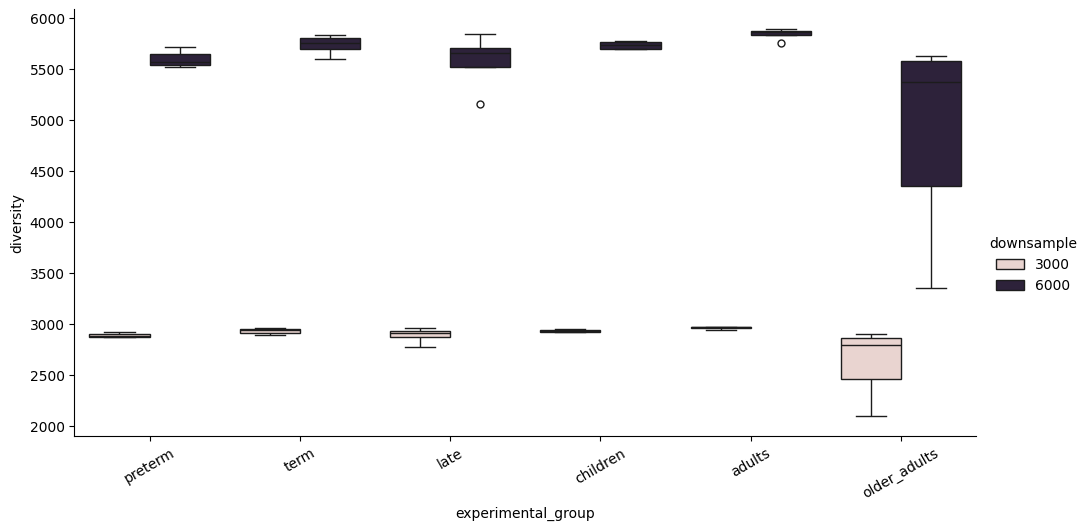

In [42]:
sns.catplot(data=depth_comparison, x="experimental_group", y="diversity", hue="downsample",
            kind="box", height=5, aspect=2)
plt.xticks(rotation=30)
plt.show()

При уменьшении глубины с 6000 до 3000 медианы diversity снижаются до 2791–2964. Порядок групп по медиане сохраняется. Самое высокое значение остаётся у adults, самое низкое у older_adults. То есть эта закономерность устойчива к проверенному изменению глубины

## Выводы

В анализ вошли все 27 образцов. При глубине 6000 наибольшая медиана diversity наблюдается в adults, наименьшая в older_adults. У older_adults выше clonality и доля крупнейшего клона. Порядок групп по diversity сохраняется при глубине 3000.

В preterm CDR3 короче, вставок меньше, а convergence выше. Среди V-сегментов в среднем лидируют TRBV12-3, TRBV5-1 и TRBV7-9, среди J-сегментов TRBJ2-7 и TRBJ2-1. Лидирующий V-сегмент различается между группами.

Сходство F2 выше всего внутри preterm. MDS показывает перекрытие групп и большой разброс older_adults. Кривые rarefaction продолжают расти. Все различия описательные, статистическая значимость не проверялась.